# Week 4: Map your set

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. The outputs below are from the 56 museum chairs in the week 4 slides.

## 1. Setup

This loads CLIP, which takes about a minute.

In [1]:
import glob, io, os, sys, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install umap-learn
import numpy as np, torch, umap
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the museum chairs. To use your own images, set it to False and run the cell again, and it will ask for a zip of your 20 to 40 designs.

In [2]:
USE_EXAMPLE = True  # True: the 56 museum chairs. False: upload a zip of your own images.
TRAIN_DIR = "train"

def unzip_upload(folder):
    """Ask for a zip of images (or several image files) and put them in `folder`."""
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, data in files.upload().items():
        if name.lower().endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(data)).extractall(folder)
        else:
            open(os.path.join(folder, name), "wb").write(data)

if USE_EXAMPLE:
    import csv, requests
    base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
    names = [r["file"] for r in csv.DictReader(io.StringIO(requests.get(base + "credits.csv", timeout=60).text))]
    os.makedirs(TRAIN_DIR, exist_ok=True)
    for f in names:
        open(os.path.join(TRAIN_DIR, f), "wb").write(requests.get(f"{base}train/{f}", timeout=60).content)
    print("downloaded the example:", len(names), "chairs")
else:
    print("Pick a zip of your images:")
    unzip_upload(TRAIN_DIR)

downloaded the example: 56 chairs


## 3. Embed your images

This turns each image into 512 numbers with CLIP.

In [3]:
EXT = (".jpg", ".jpeg", ".png", ".webp")
def images_in(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if p.lower().endswith(EXT) and "__MACOSX" not in p)

def embed(paths):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), 16):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + 16]]
            e = model.get_image_features(**proc(images=ims, return_tensors="pt").to(dev))
            if not torch.is_tensor(e):  # newer versions of transformers return an object
                e = e.image_embeds if getattr(e, "image_embeds", None) is not None else e.pooler_output
                if e.shape[-1] != model.config.projection_dim:
                    e = model.visual_projection(e)
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

train = images_in(TRAIN_DIR)
E = embed(train)
print(len(train), "images")

56 images


## 4. Map

Images with similar numbers are placed close together. If two groups are far apart, you can use them as the two ends of a slider in week 5.

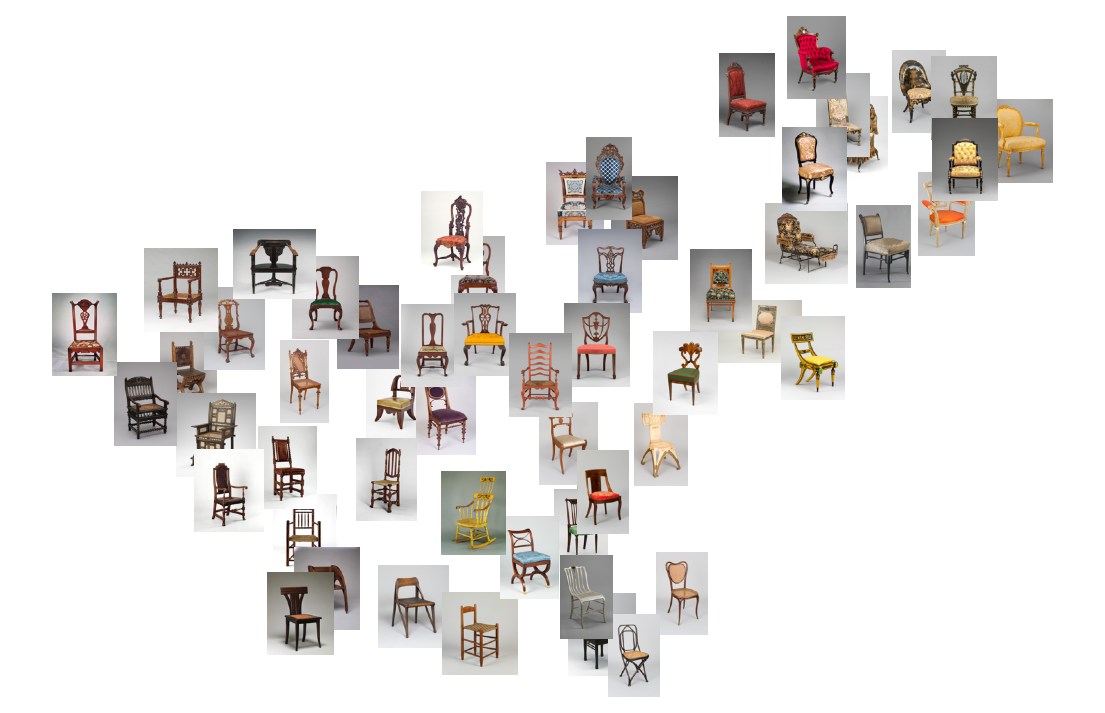

In [4]:
reducer = umap.UMAP(n_neighbors=min(15, len(train) - 1), min_dist=0.3, metric="cosine", random_state=0)
xy = reducer.fit_transform(E)

def thumb(ax, path, x, y, size=0.5):
    im = Image.open(path).convert("RGB")
    im.thumbnail((120, 120))
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(im), zoom=size), (x, y), frameon=False))

fig, ax = plt.subplots(figsize=(14, 9))
for (x, y), p in zip(xy, train):
    thumb(ax, p, x, y)
pad = (xy.max(0) - xy.min(0)) * 0.08
ax.set_xlim(xy[:, 0].min() - pad[0], xy[:, 0].max() + pad[0])
ax.set_ylim(xy[:, 1].min() - pad[1], xy[:, 1].max() + pad[1])
ax.axis("off")
plt.savefig("map.jpg", dpi=120, bbox_inches="tight")
plt.show()

## 5. Search with words

You can change WORDS to your own words and run the cell again. It shows the four closest images for each word. For the hand-in, you can download map.jpg from the Files panel on the left.

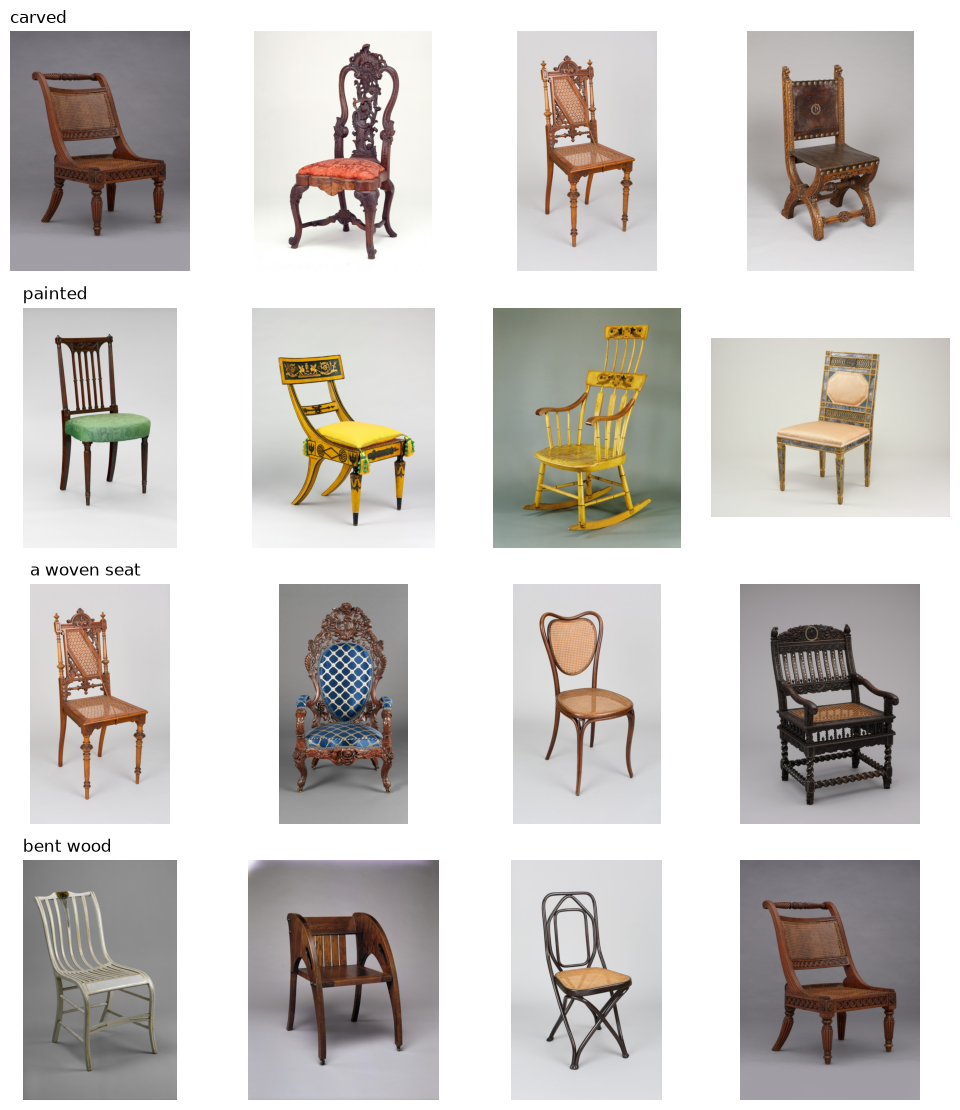

In [5]:
WORDS = ["carved", "painted", "a woven seat", "bent wood"]  # try your own words

with torch.no_grad():
    t = model.get_text_features(**proc(text=[f"a photo of a chair with {w}" if w.startswith("a ") else f"a photo of a {w} chair" for w in WORDS], return_tensors="pt", padding=True).to(dev))
    if not torch.is_tensor(t):
        t = t.text_embeds if getattr(t, "text_embeds", None) is not None else t.pooler_output
        if t.shape[-1] != model.config.projection_dim:
            t = model.text_projection(t)
    T = torch.nn.functional.normalize(t, dim=-1).cpu().numpy()
S = T @ E.T
fig, axes = plt.subplots(len(WORDS), 4, figsize=(10, 2.8 * len(WORDS)), squeeze=False)
for i, w in enumerate(WORDS):
    for k, j in enumerate(np.argsort(-S[i])[:4]):
        axes[i, k].imshow(Image.open(train[j]).convert("RGB"))
        axes[i, k].axis("off")
    axes[i, 0].set_title(w, loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("search.jpg", dpi=110)
plt.show()